In [1]:
import numpy as np
from scipy.stats import gaussian_kde

import jax
import jax.numpy as jnp
import jax.scipy as jsp
import jax.random as jr
jax.config.update("jax_enable_x64", True)
import equinox as eqx
import optax
import matplotlib.pyplot as plt
from tqdm import trange
import pickle 
import os

from flowjax.distributions import StandardNormal, Transformed
from flowjax.bijections import Coupling, RationalQuadraticSpline, Chain, Permute, Affine

In [2]:
ex_res_path = 'example_res.npy'
limit = 100000
with open(ex_res_path, 'rb') as f:
        ex_res = pickle.load(f)

evol_z = ex_res.evol_z[:limit]
factor = ex_res.factor[:limit]
n_individuals = evol_z.shape[1]

# Calculate Burn-in
factor1 = np.where(factor == 1)[0]
burn_in_idx = factor1[-1] if len(factor1) > 0 else int(limit * 0.2)

# Calculate MAP / Posterior Mean for each individual
print(f"Calculating Posterior Mean (MAP) using iterations {burn_in_idx} to {evol_z.shape[0]}...")
valid_z_samples = evol_z[burn_in_idx:, :, :]
map_z = np.mean(valid_z_samples, axis=0)  # Shape: (n_individuals, 3)

latent_names = ['Asymptotic (z_0)', 'Inflexion (z_1)', 'Tau (z_2)']

An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.


Calculating Posterior Mean (MAP) using iterations 3985 to 100000...


In [3]:
# ==========================================
# 1. Define the 3D GMM Dataset
# ==========================================
class Params:
    def __init__(self):
        self.asymptotic = 200.0
        self.inflexion = 500.0
        self.tau = 150.0
        self.cov_latent = jnp.diag(jnp.array([40.0, 100.0, 100.0]))

def sample_gmm_data(key, n):
    p = Params()
    key1, key_mean, key_comp, key_norm = jax.random.split(key, 4)
    
    base_mean = jnp.array([p.asymptotic, p.inflexion, p.tau])
    L = jnp.linalg.cholesky(p.cov_latent)
    spread = 100.0 
    
    gmm_means = base_mean + jax.random.normal(key_mean, shape=(3, 3)) * spread
    components = jax.random.randint(key_comp, shape=(n, 3), minval=0, maxval=3)
    assigned_means = gmm_means[components, jnp.arange(3)] 
    
    z = jax.random.normal(key_norm, shape=(n, 3)) @ L.T + assigned_means
    return z

In [ ]:

key = jr.PRNGKey(42)
key, subkey = jr.split(key)
x_train = map_z 
num_samples = int(x_train.shape[0])

print(f"Generated {num_samples} 3D samples.")
print(f"Data Means: {jnp.mean(x_train, axis=0)}")
print(f"Data Std: {jnp.std(x_train, axis=0)}\n")

# ==========================================
# 2. Define the Multi-Layer Architecture
# ==========================================
bound = 5.0
K = 8
num_layers = 16  # Number of coupling layers
base_dist = StandardNormal((3,))


loc = jnp.mean(x_train, axis=0)
scale = jnp.std(x_train, axis=0)
renormalizer = Affine(loc=loc, scale=scale)


layers = []


flow_key = jr.PRNGKey(127)
for i in range(num_layers):
    flow_key, subkey1= jr.split(flow_key, 2)
    
    layers.append(Coupling(
        key=subkey1,
        transformer=RationalQuadraticSpline(knots=K, interval=bound),
        untransformed_dim=2,  
        dim=3,
        nn_width=32,
        nn_depth=2
    ))
    
    
    permutation = jnp.roll(jnp.arange(3), shift=1)
    layers.append(Permute(permutation))

layers.append(renormalizer)

# Compose the full bijection and flow
bijection = Chain(layers)
flow = Transformed(base_dist, bijection)

Generated 10000 3D samples.
Data Means: [199.90628214 560.45045101 141.91254705]
Data Std: [41.32316889 42.83389685 19.78528396]



In [5]:
# 1. Train/Validation Split (90/10)
num_train = int(0.9 * num_samples)
x_train_split = x_train[:num_train]
x_val_split = x_train[num_train:]

# 2. Add Regularization via AdamW (Weight Decay)
learning_rate = 5e-3
weight_decay = 1e-4
optim = optax.adamw(learning_rate, weight_decay=weight_decay)
opt_state = optim.init(eqx.filter(flow, eqx.is_inexact_array))

# 3. Component Extraction Function
@eqx.filter_vmap(in_axes=(None, 0))
def compute_components(model, x):
    # flow.log_prob(x) = log P_Z(f^{-1}(x)) + log |det J_{f^{-1}}(x)|
    z, log_det = model.bijection.inverse_and_log_det(x)
    base_log_prob = model.base_dist.log_prob(z)
    return base_log_prob, log_det

@eqx.filter_value_and_grad(has_aux=True)
def loss_fn(model, x):
    base_log_prob, log_det = compute_components(model, x)
    avg_base = jnp.mean(base_log_prob)
    avg_det = jnp.mean(log_det)
    loss = -(avg_base + avg_det)
    return loss, (avg_base, avg_det)

@eqx.filter_jit
def train_step(model, state, x):
    # Ensure we pass the filtered model parameters to apply weight decay correctly
    params = eqx.filter(model, eqx.is_inexact_array)
    (loss, (avg_base, avg_det)), grads = loss_fn(model, x)
    updates, new_state = optim.update(grads, state, params)
    model = eqx.apply_updates(model, updates)
    return model, new_state, loss, avg_base, avg_det

@eqx.filter_jit
def eval_step(model, x):
    base_log_prob, log_det = compute_components(model, x)
    return -jnp.mean(base_log_prob + log_det)

# 4. Training Loop with Tracking
epochs = 3000
batch_size = 1024
num_batches = num_train // batch_size

history = {
    "train_loss": [], "val_loss": [], 
    "base_log_prob": [], "log_det": []
}

pbar = trange(epochs, desc="Training Flow")
for epoch in pbar:
    key, subkey = jax.random.split(key)
    indices = jax.random.permutation(subkey, num_train)
    
    epoch_train_loss, epoch_base, epoch_det = 0.0, 0.0, 0.0
    
    for i in range(num_batches):
        batch_indices = indices[i * batch_size : (i + 1) * batch_size]
        x_batch = x_train_split[batch_indices]
        
        flow, opt_state, loss, avg_base, avg_det = train_step(flow, opt_state, x_batch)
        epoch_train_loss += loss
        epoch_base += avg_base
        epoch_det += avg_det
        
    # Calculate epoch averages
    avg_train_loss = epoch_train_loss / num_batches
    avg_val_loss = eval_step(flow, x_val_split)
    
    history["train_loss"].append(avg_train_loss)
    history["val_loss"].append(avg_val_loss)
    history["base_log_prob"].append(epoch_base / num_batches)
    history["log_det"].append(epoch_det / num_batches)
    
    pbar.set_postfix(t_loss=f"{avg_train_loss:.2f}", v_loss=f"{avg_val_loss:.2f}")



Training Flow: 100%|██████████| 3000/3000 [16:29<00:00,  3.03it/s, t_loss=13.09, v_loss=13.60]


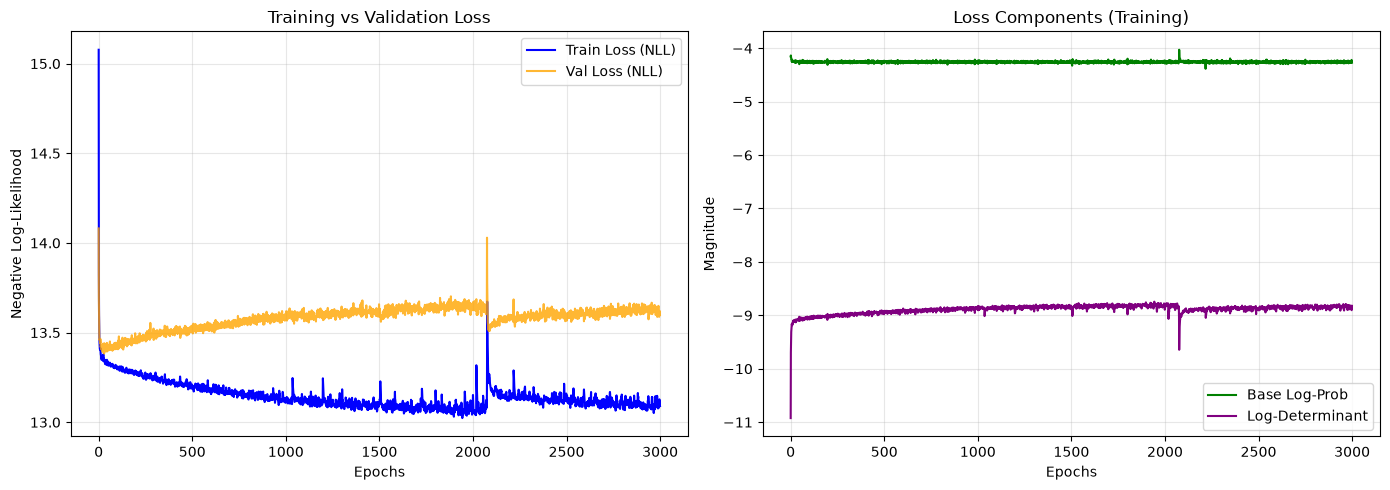

In [7]:
# 5. Plotting the Learning Curves
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Train vs Validation Loss
ax1.plot(history["train_loss"], label="Train Loss (NLL)", color="blue")
ax1.plot(history["val_loss"], label="Val Loss (NLL)", color="orange", alpha=0.8)
ax1.set_title("Training vs Validation Loss")
ax1.set_xlabel("Epochs")
ax1.set_ylabel("Negative Log-Likelihood")
ax1.legend()
ax1.grid(alpha=0.3)

# Plot 2: Base Log-Prob vs Log-Determinant
ax2.plot(history["base_log_prob"], label="Base Log-Prob", color="green")
ax2.plot(history["log_det"], label="Log-Determinant", color="purple")
ax2.set_title("Loss Components (Training)")
ax2.set_xlabel("Epochs")
ax2.set_ylabel("Magnitude")
ax2.legend()
ax2.grid(alpha=0.3)

plt.tight_layout()
plt.show()

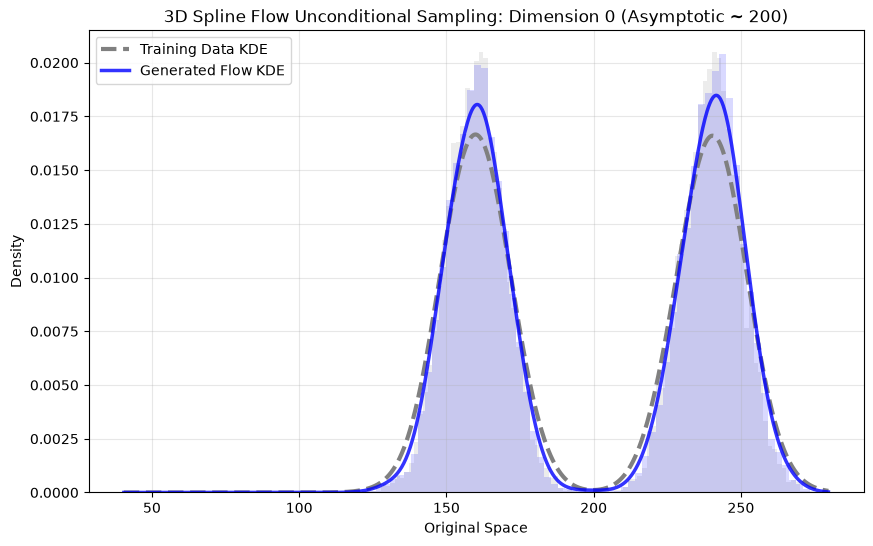

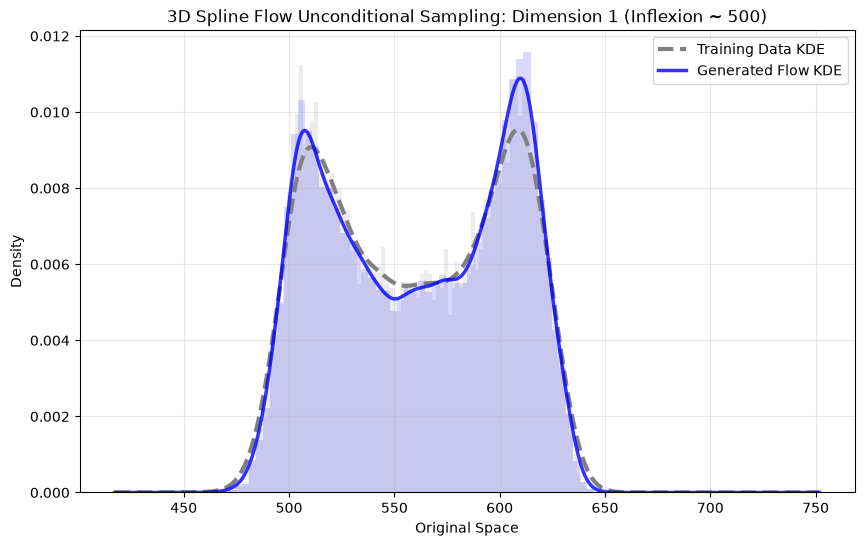

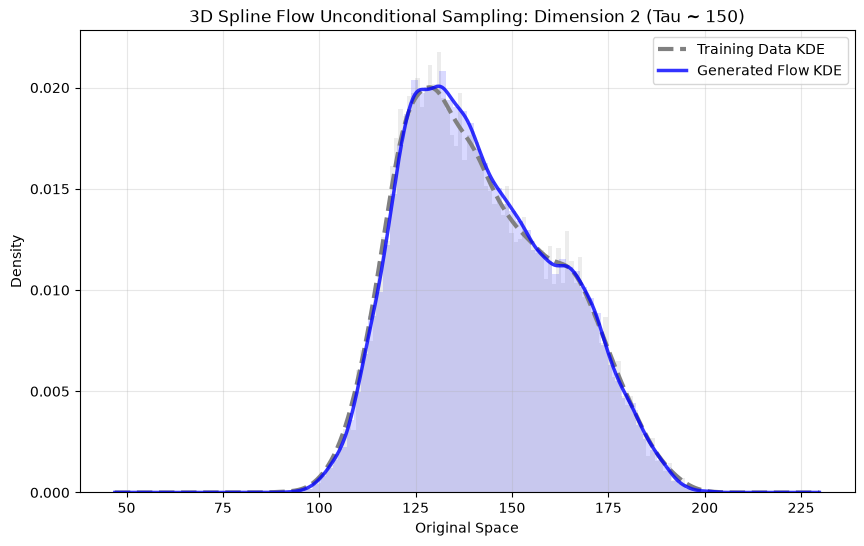

In [8]:
# ==========================================
# 5. Unconditional Sampling and KDE Visualization
# ==========================================
# Draw 10,000 samples from the trained normalizing flow
sample_key = jax.random.key(999)
num_generated_samples = 100000
x_generated = flow.sample(sample_key, (num_generated_samples,))

dim_names = [
    "Dimension 0 (Asymptotic ~ 200)", 
    "Dimension 1 (Inflexion ~ 500)", 
    "Dimension 2 (Tau ~ 150)"
]

for d in range(3):
    plt.figure(figsize=(10, 6))
    
    # Convert to NumPy for SciPy KDE
    train_data_1d = np.array(x_train[:, d])
    gen_data_1d = np.array(x_generated[:, d])
    
    # Create an evaluation grid based on data bounds
    min_val = min(train_data_1d.min(), gen_data_1d.min())
    max_val = max(train_data_1d.max(), gen_data_1d.max())
    x_grid = np.linspace(min_val, max_val, 1000)
    
    # Fit KDEs
    kde_train = gaussian_kde(train_data_1d)
    kde_gen = gaussian_kde(gen_data_1d)
    
    # Plot KDE curves
    plt.plot(x_grid, kde_train(x_grid), color='gray', linewidth=3, linestyle='--', label="Training Data KDE")
    plt.plot(x_grid, kde_gen(x_grid), color='blue', linewidth=2.5, alpha=0.8, label="Generated Flow KDE")
    
    # Add light histograms in the background for visual context
    plt.hist(train_data_1d, bins=100, density=True, alpha=0.15, color='gray')
    plt.hist(gen_data_1d, bins=100, density=True, alpha=0.15, color='blue')
    
    plt.title(f"3D Spline Flow Unconditional Sampling: {dim_names[d]}")
    plt.xlabel("Original Space")
    plt.ylabel("Density")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.show()

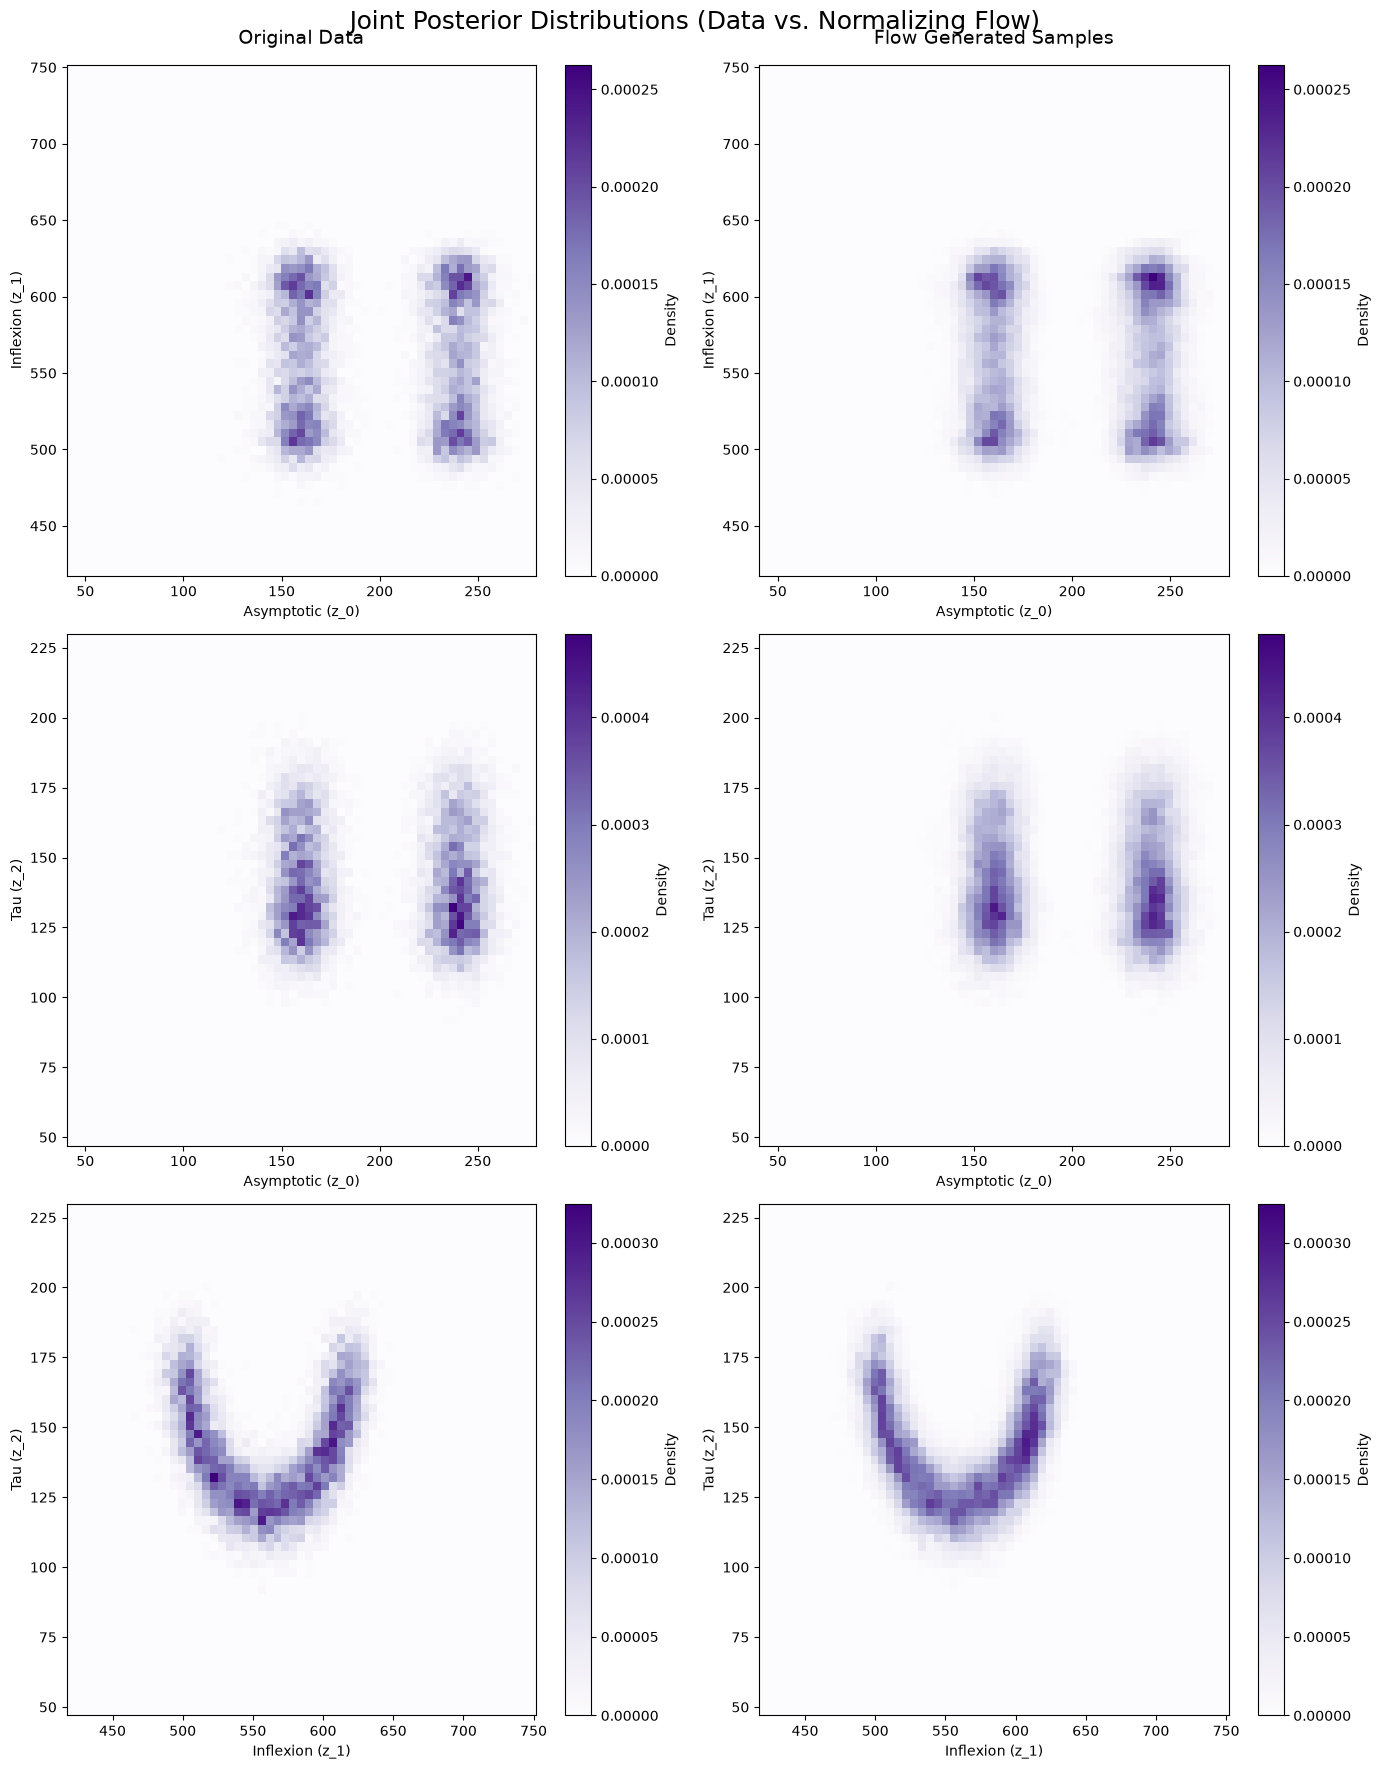

In [ ]:
pairs = [(0, 1), (0, 2), (1, 2)]
latent_names = ['Asymptotic (z_0)', 'Inflexion (z_1)', 'Tau (z_2)']

fig, axes = plt.subplots(3, 2, figsize=(14, 18))

for i, (d1, d2) in enumerate(pairs):

    min_x = min(x_train[:, d1].min(), x_generated[:, d1].min())
    max_x = max(x_train[:, d1].max(), x_generated[:, d1].max())
    min_y = min(x_train[:, d2].min(), x_generated[:, d2].min())
    max_y = max(x_train[:, d2].max(), x_generated[:, d2].max())
    
    bins_x = np.linspace(min_x, max_x, 60)
    bins_y = np.linspace(min_y, max_y, 60)
    
    # 2. Pre-calculate histograms to find the global max density for the colorbar scale
    h_train, _, _ = np.histogram2d(x_train[:, d1], x_train[:, d2], bins=[bins_x, bins_y], density=True)
    h_gen, _, _ = np.histogram2d(x_generated[:, d1], x_generated[:, d2], bins=[bins_x, bins_y], density=True)
    global_vmax = max(h_train.max(), h_gen.max())
    
    # --- Left Column: Original Data ---
    _, _, _, im1 = axes[i, 0].hist2d(
        x_train[:, d1], x_train[:, d2], 
        bins=[bins_x, bins_y], cmap='Purples', density=True, vmin=0, vmax=global_vmax
    )
    axes[i, 0].set_xlabel(latent_names[d1])
    axes[i, 0].set_ylabel(latent_names[d2])
    fig.colorbar(im1, ax=axes[i, 0], label='Density')
    
    # --- Right Column: Generated Samples ---
    _, _, _, im2 = axes[i, 1].hist2d(
        x_generated[:, d1], x_generated[:, d2], 
        bins=[bins_x, bins_y], cmap='Purples', density=True, vmin=0, vmax=global_vmax
    )
    axes[i, 1].set_xlabel(latent_names[d1])
    axes[i, 1].set_ylabel(latent_names[d2])
    fig.colorbar(im2, ax=axes[i, 1], label='Density')

    # Set column titles on the first row only
    if i == 0:
        axes[i, 0].set_title("Original Data", fontsize=14, pad=15)
        axes[i, 1].set_title("Flow Generated Samples", fontsize=14, pad=15)

plt.suptitle("Joint Posterior Distributions (Data vs. Normalizing Flow)", fontsize=18, y=0.98)
plt.tight_layout()
plt.show()